# Project 1, Phase 2: Fake patients, neural encoder

This notebook stands alone. You do not need Phase 1 open.

Goal: prove the network can recover hidden parameters. We make fake patients where we know the true answers, then check whether the encoder finds them.

## The hidden rule

Each fake patient has 50 random numbers (fake genes). The true clearance comes from genes 0 to 4, and the true growth rate comes from genes 5 to 9, through a fixed rule. The other 40 genes are noise. The network never sees the rule, only the genes. It must learn to ignore the noise genes.

Fixed numbers, same as Phase 1: Dose 500 mg, V 50 L, K 100, kill 0.05, starting tumour 10, 30 days.

In [1]:
import torch
from torchdiffeq import odeint
import matplotlib.pyplot as plt

torch.manual_seed(0)

DOSE = 500.0
V = 50.0
K = 100.0
KILL = 0.05
T0 = 10.0
N = 200
G = 50

X = torch.randn(N, G)
w_cl = torch.randn(5) / (5 ** 0.5)
w_g = torch.randn(5) / (5 ** 0.5)
true_CL = 7.5 * torch.exp(0.25 * (X[:, 0:5] @ w_cl))
true_growth = 0.2 * torch.exp(0.25 * (X[:, 5:10] @ w_g))

def simulate(CL, growth, t):
    ke = CL / V
    def ode(tt, y):
        C, T = y[:, 0], y[:, 1]
        dC = -ke * C
        dT = growth * T * (1 - T / K) - KILL * C * T
        return torch.stack([dC, dT], dim=1)
    y0 = torch.stack([torch.full_like(CL, DOSE / V), torch.full_like(CL, T0)], dim=1)
    return odeint(ode, y0, t, method="rk4", options={"step_size": 1.0})

t = torch.linspace(0, 30, 31)
true_sol = simulate(true_CL, true_growth, t)
true_C, true_T = true_sol[:, :, 0], true_sol[:, :, 1]
print("True CL range:", round(true_CL.min().item(), 1), "to", round(true_CL.max().item(), 1))
print("True growth range:", round(true_growth.min().item(), 3), "to", round(true_growth.max().item(), 3))
print("Ground truth curves:", tuple(true_sol.shape), "(days, patients, state)")

True CL range: 2.8 to 17.5
True growth range: 0.102 to 0.38
Ground truth curves: (31, 200, 2) (days, patients, state)


## The encoder and training

Small network: 50 inputs, one hidden layer of 32, output 2 numbers. The outputs are mapped to positive parameters around the population means (CL 7.5, growth 0.2) and clamped, so parameters stay sane. Loss compares predicted curves to true curves, with each curve divided by its typical size so both count equally. Fixed-step RK4, one step per day, keeps training fast and stable.

In [2]:
encoder = torch.nn.Sequential(
    torch.nn.Linear(G, 32), torch.nn.ReLU(),
    torch.nn.Linear(32, 2))
opt = torch.optim.Adam(encoder.parameters(), lr=0.01)

for step in range(301):
    opt.zero_grad()
    raw = encoder(X)
    pred_CL = 7.5 * torch.exp(torch.clamp(raw[:, 0], -2, 2))
    pred_growth = 0.2 * torch.exp(torch.clamp(raw[:, 1], -2, 2))
    pred_sol = simulate(pred_CL, pred_growth, t)
    pred_C, pred_T = pred_sol[:, :, 0], pred_sol[:, :, 1]
    loss = ((pred_C / 10 - true_C / 10) ** 2).mean() + ((pred_T / 50 - true_T / 50) ** 2).mean()
    loss.backward()
    opt.step()
    if step % 50 == 0:
        print("step", step, "loss", round(loss.item(), 4))
print("final loss", round(loss.item(), 4))

step 0 loss 0.1819


step 50 loss 0.0007


step 100 loss 0.0001


step 150 loss 0.0


step 200 loss 0.0


step 250 loss 0.0


step 300 loss 0.0
final loss 0.0


CL correlation: 0.995
Growth correlation: 0.995


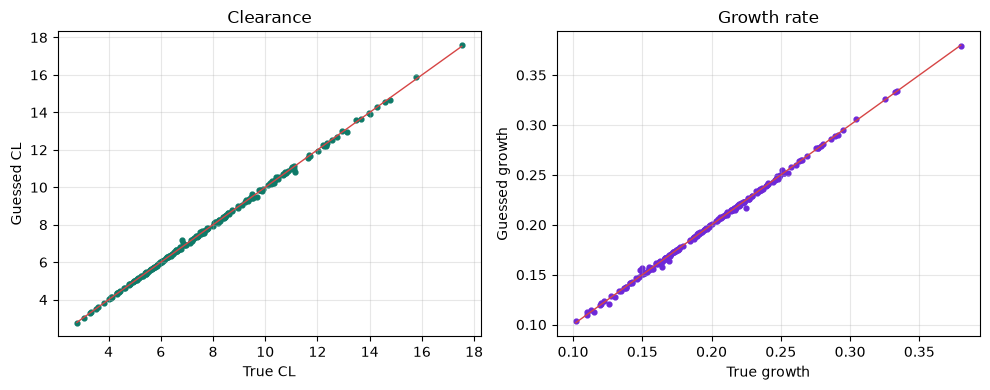

In [3]:
with torch.no_grad():
    raw = encoder(X)
    pred_CL = 7.5 * torch.exp(torch.clamp(raw[:, 0], -2, 2))
    pred_growth = 0.2 * torch.exp(torch.clamp(raw[:, 1], -2, 2))

def corr(a, b):
    a = a - a.mean()
    b = b - b.mean()
    return ((a * b).mean() / (a.std() * b.std())).item()

print("CL correlation:", round(corr(pred_CL, true_CL), 3))
print("Growth correlation:", round(corr(pred_growth, true_growth), 3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(true_CL.numpy(), pred_CL.numpy(), s=12, color="#0E7A68")
axes[0].plot([true_CL.min(), true_CL.max()], [true_CL.min(), true_CL.max()], color="#D64545", linewidth=1)
axes[0].set_xlabel("True CL")
axes[0].set_ylabel("Guessed CL")
axes[0].set_title("Clearance")
axes[0].grid(True, alpha=0.3)
axes[1].scatter(true_growth.numpy(), pred_growth.numpy(), s=12, color="#6D28D9")
axes[1].plot([true_growth.min(), true_growth.max()], [true_growth.min(), true_growth.max()], color="#D64545", linewidth=1)
axes[1].set_xlabel("True growth")
axes[1].set_ylabel("Guessed growth")
axes[1].set_title("Growth rate")
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Check

If the dots sit near the red diagonal line in both plots, Phase 2 passes: the encoder recovered hidden parameters from genes alone, ignoring 40 noise genes. If the dots scatter widely, train longer or lower the learning rate (0.01 to 0.005) and run again.

Milestone: the machinery works on data where you know the answer. Save a copy in Drive, then tell Muse to start Phase 3.